<div style="text-align: right"><sub>This notebook is distributed under the <a href="https://creativecommons.org/licenses/by-sa/3.0/" target="_blank">Attribution-ShareAlike 3.0 International (CC BY-SA 3.0) license</a>.</sub></div>
<h1>Curs d'Òptica en Python <span style="font-size:10px;"> <i>Jupyter notbooks collection by <a href="https://webgrec.ub.edu/webpages/000004/cat/dmaluenda.ub.edu.html" target="_blank">David Maluenda</a></i></span></h1>

<table class="tfo-notebook-buttons" align="left">
  <td>
    <a href="https://campusvirtual.ub.edu/my" target="_blank">
      <img src="https://github.com/dmaluenda/hands_on_machine_learning/raw/master/resources/ub_logo-01.png" width="130"/>
    </a>
  </td>
  <td>
     &#160 &#160 &#160 &#160 &#160
  </td>
  <td>   <!-- gColab -->
    <a href="https://colab.research.google.com/github/opticaUB/material_classe/blob/main/23_Prop_FresnelCoeff_widgets.ipynb" target="_blank">
      <img src="https://github.com/dmaluenda/hands_on_machine_learning/raw/master/resources/colab_logo_32px.png" />
      Run in Google Colab
    </a>
  </td>
  <td>
     &#160 &#160 &#160 &#160 &#160
  </td>
  <td>   <!-- github -->
    <a href="https://github.com/opticaUB/material_classe/blob/main/23_Prop_FresnelCoeff_widgets.ipynb" target="_blank">
      <img src="https://github.com/dmaluenda/hands_on_machine_learning/raw/master/resources/github_logo_32px.png" />
      View source on GitHub
    </a>
  </td>
  <td>
      &#160 &#160 &#160 &#160 &#160
  </td>
  <td>   <!-- download -->
    <a href="https://raw.githubusercontent.com/opticaUB/material_classe/main/23_Prop_FresnelCoeff_widgets.ipynb"  target="_blank"
          download="02_Training">
      <img src="https://github.com/dmaluenda/hands_on_machine_learning/raw/master/resources/download_logo_32px.png" />
      Download notebook
      </a>
  </td>
</table>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import animation
from mpl_toolkits.axes_grid1 import ImageGrid

import ipywidgets as widgets
from IPython.display import display, HTML

try:  # gColab: activa el gestor de widgets
    from google.colab import output
    output.enable_custom_widget_manager()
except ImportError:
    pass


Definim els eixos $XZ$ pel pla d'incidència. Addicionalment, definim unes màscares (de valor $0$ o $1$) d'on s'ha de calcular els camps incidents, reflectit i transmés.

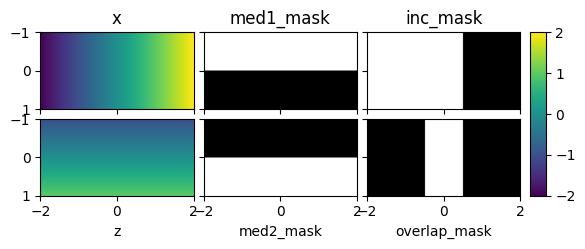

In [2]:
def get_coords(overlap=0.5, verbose=False):

    N_points = 300
    rang = np.linspace(-1, 1, N_points)
    x, z = np.meshgrid(rang, rang)
    x = 2*x
    
    inc_mask = (x<overlap)
    refl_mask = (x>-overlap)
    med1_mask = z<0
    med2_mask = z>0

    if verbose:
        fig = plt.figure(figsize=(30,15))
        axs = ImageGrid(fig, 142,
                         nrows_ncols=(2, 3), axes_pad=0.1, label_mode="L", share_all=True,
                         cbar_location="right", cbar_mode="single")
        
        im = axs[0].imshow(x, extent=[-2,2,1,-1], vmin=-2, vmax=2)
        axs[0].set_title("x")
        
        axs[1].imshow(med1_mask, extent=[-2,2,1,-1], cmap='gray')
        axs[1].set_title("med1_mask")

        axs[2].imshow(inc_mask, extent=[-2,2,1,-1], cmap='gray')
        axs[2].set_title("inc_mask")
        
        axs[3].imshow(z, extent=[-2,2,1,-1], vmin=-2, vmax=2)
        axs[3].set_xlabel("z")
        
        axs[4].imshow(med2_mask, extent=[-2,2,1,-1], cmap='gray')
        axs[4].set_xlabel("med2_mask")

        axs[5].imshow(inc_mask*refl_mask, extent=[-2,2,1,-1], cmap='gray')
        axs[5].set_xlabel("overlap_mask")
        
        axs.cbar_axes[0].colorbar(im)

    return x, z, inc_mask*med1_mask, med2_mask, refl_mask*med1_mask

_ = get_coords(0.5, True)

In [6]:
def main(wavelen0, theta1_d, n1, n2, k2, mode, overlap, maxim, n_frames=16):

    #%% Basic parameters %%
    k0 = 2 * np.pi / wavelen0  # vacum wavenumber in microns^-1
    theta1 = np.radians(theta1_d)
    sin_theta1 = np.sin(theta1)
    cos_theta1 = np.cos(theta1)

    # theta2 and its trigonometrics
    n2_hat = n2 - 1j*k2  # complex refractive index
    sin_theta2 = n1 * sin_theta1 / n2_hat
    theta2 = np.arcsin(sin_theta2 + 0j)
    cos_theta2 = np.cos(theta2)

    # Fresnel coeff.
    ts = 2*np.cos(theta1)*np.sin(theta2) / np.sin(theta2+theta1)
    tp = ts / np.cos(theta2-theta1)

    rs = np.sin(theta2-theta1) / np.sin(theta2+theta1)
    rp = np.tan(theta2-theta1) / np.tan(theta2+theta1)

    r = rp if mode=="p" else rs
    t = tp if mode=="p" else ts

    # coords and plotting masks
    x, z, inc_mask, trans_mask, refl_mask = get_coords(overlap)

    #%% Stationary waves (spatial part, computed only once) %%
    Amp_inc = 1
    prop_inc = np.exp(-1j*k0*n1*(x*sin_theta1+z*cos_theta1))

    Amp_refl = r * Amp_inc
    prop_refl = np.exp(-1j*k0*n1*(x*sin_theta1-z*cos_theta1))

    Amp_trans = t * Amp_inc
    prop_trans = np.exp(-1j*k0*n2_hat*(x*sin_theta2+z*cos_theta2))

    E_spatial = (Amp_inc*prop_inc*inc_mask + Amp_refl*prop_refl*refl_mask
                 + Amp_trans*prop_trans*trans_mask)

    maxim_ = maxim or np.abs(E_spatial).max()

    #%% Temporal evolution: one full period, sampled in n_frames phases %%
    phases = np.linspace(0, 2*np.pi, n_frames, endpoint=False)

    fig, ax = plt.subplots(figsize=(8, 4), dpi=72)
    im = ax.imshow(np.real(E_spatial), vmin=-maxim_, vmax=maxim_, cmap='RdBu',
                   extent=[-2, 2, -1, 1], animated=True)
    ax.plot([-2, 2], [0, 0], '-k', linewidth=3)  # interface line
    ax.set_axis_off()
    fig.colorbar(im, ax=ax)
    ax.set_title(f"mode {mode}:  |r| = {abs(r):.3f},  |t| = {abs(t):.3f}")

    def update(phase):
        im.set_data(np.real(E_spatial * np.exp(1j*phase)))  # e^{-i w t}
        return (im,)

    anim = animation.FuncAnimation(fig, update, frames=phases, interval=80, blit=True)
    html = anim.to_jshtml(default_mode='loop')
    plt.close(fig)  # avoid a duplicated static figure
    return HTML(html)

Mou els *sliders* i prem **Calcula** per generar l'animació (un període complet en bucle). Fes servir els controls de reproducció per aturar-la, anar frame a frame o canviar-ne la velocitat.

In [7]:
style = {'description_width': '160px'}
layout = widgets.Layout(width='480px')
sl = lambda cls, **kw: cls(style=style, layout=layout, continuous_update=False, **kw)

w_wavelen = sl(widgets.FloatSlider, value=0.520, min=0.2, max=1.5, step=0.01, description='λ₀ (µm)')
w_theta   = sl(widgets.FloatSlider, value=30, min=0, max=89.9, step=0.5, description='θ₁ (graus)')
w_n1      = sl(widgets.FloatSlider, value=1.0, min=1.0, max=3.0, step=0.01, description='n₁')
w_n2      = sl(widgets.FloatSlider, value=1.5, min=1.0, max=3.0, step=0.01, description='n₂')
w_k2      = sl(widgets.FloatSlider, value=0.0, min=0.0, max=3.0, step=0.01, description='κ₂ (extinció)')
w_overlap = sl(widgets.FloatSlider, value=1.0, min=0.0, max=2.0, step=0.05, description='overlap inc./refl.')
w_maxim   = sl(widgets.FloatSlider, value=1.0, min=0.1, max=3.0, step=0.1, description='escala de color')
w_mode    = widgets.ToggleButtons(options=['s', 'p'], value='s', description='polarització', style=style)
w_button  = widgets.Button(description='Calcula', button_style='primary', icon='play')

out = widgets.Output()

def on_click(_=None):

    print(f"angle Brewster: {np.degrees(np.arctan(w_n2.value/w_n1.value)):.2f} º")
    print(f"angle límit: {str(np.degrees(np.arcsin(w_n2.value/w_n1.value)),'%.2f')+'º' if w_n2.value < w_n1.value else 'not exist'}")
    
    w_button.disabled = True
    w_button.description = 'Calculant...'
    try:
        anim = main(w_wavelen.value, w_theta.value, w_n1.value, w_n2.value, w_k2.value,
                    w_mode.value, w_overlap.value, w_maxim.value)
        with out:
            out.clear_output(wait=True)
            display(anim)
    finally:
        w_button.disabled = False
        w_button.description = 'Calcula'

w_button.on_click(on_click)

display(widgets.VBox([w_wavelen, w_theta, w_n1, w_n2, w_k2, w_mode,
                      w_overlap, w_maxim, w_button, out]))
on_click()

angle Brewster: 56.31 º
angle límit: not exist
